# UPI Fraud Detection - EDA

This notebook starts the machine learning workflow for the behavioral fraud dataset.

Goals for this notebook:
- load the dataset
- inspect the schema and target distribution
- check for missing values and class imbalance
- prepare a clean base for feature analysis and model training

## 1. Imports and Dataset Load

The dataset is stored in the repository `dataset/` folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('..') / 'dataset' / 'upi_fraud_dataset_behavioral_v2.csv'
df = pd.read_csv(DATA_PATH)

df.head()

,transaction_id,transaction_date,transaction_time,customer_id,sender_upi,receiver_upi,amount,transaction_type,merchant_category,sender_account_age_days,receiver_account_age_days,device_id,device_changed,known_device,trusted_device,os_type,app_name,ip_address,location,location_changed,new_beneficiary,beneficiary_frequency,transactions_last_10_minutes,transactions_last_hour,transactions_last_24_hours,amount_sent_last_24_hours,amount_received_last_24_hours,unique_receivers_today,balance_before,balance_after,decimal_pattern,money_flow_pattern,customer_behaviour_deviation,is_fraud,fraud_type
0,TXN0096196,2026-04-07,00:07:47,CUST02924,ishaantank6535@okhdfcbank,vsingh6378@paytm,745.21,P2P,NaN,124,235,DEV-48EA6BD0FFEE,False,True,True,Android,Paytm,58.35.75.178,Pune,False,True,0,0,0,0,0.0,0.0,0,44705.71,43960.50,False,Refund,0.2219,0,NaN
1,TXN0067907,2026-04-07,00:08:45,CUST04012,harinakshikar7902@oksbi,bahadurjitchandran9738@okhdfcbank,1230.44,P2M,Electronics,308,146,DEV-B7CD99AC4D9B,False,True,True,Android,Paytm,171.220.144.175,Mumbai,False,True,0,0,0,0,0.0,0.0,0,1269254.65,1268024.21,False,Travel Payment,0.1813,0,NaN
2,TXN0008569,2026-04-07,00:10:50,CUST02392,sathvikswamy9935@paytm,lavanyasen2814@okaxis,643.95,P2P,NaN,113,322,DEV-CDC3A225D3F6,False,True,True,Android,Paytm,130.196.162.207,Lucknow,False,True,0,0,0,0,0.0,0.0,0,343755.85,343111.90,False,Gift,0.4219,0,NaN
3,TXN0083623,2026-04-07,00:13:39,CUST01883,aayushwali4880@paytm,finnchanda3055@okicici,203.08,P2P,NaN,627,1098,DEV-3766EBCA617C,False,True,True,iOS,AmazonPay,79.123.13.235,Nagpur,False,True,0,0,0,0,0.0,0.0,0,261606.72,261403.64,False,Personal Transfer,0.2455,0,NaN
4,TXN0060281,2026-04-07,00:20:18,CUST04883,amritalalla5990@okicici,merchant8860@apl,401.43,P2M,Rent,1000,266,DEV-B50D1ADAFF11,False,True,True,Android,BHIM,92.106.65.184,Jaipur,False,True,0,0,0,0,0.0,0.0,0,120217.53,119816.10,False,Bills Payment,0.1768,0,NaN


## 2. Quick Dataset Inspection

We check the dataset size, column types, missing values, and fraud rate before moving into deeper feature analysis.

In [2]:
summary = {
    'rows': len(df),
    'columns': df.shape[1],
    'fraud_count': int(df['is_fraud'].sum()),
    'fraud_rate': float(df['is_fraud'].mean()),
}

print('Dataset summary:')
print(summary)

print('\nData types:')
print(df.dtypes)

print('\nMissing values per column:')
missing = df.isna().sum().sort_values(ascending=False)
print(missing[missing > 0] if (missing > 0).any() else 'No missing values found.')

print('\nTarget distribution:')
print(df['is_fraud'].value_counts().rename(index={0: 'Legit', 1: 'Fraud'}))

Dataset summary:
{'rows': 100000, 'columns': 35, 'fraud_count': 5000, 'fraud_rate': 0.05}

Data types:
transaction_id                    object
transaction_date                  object
transaction_time                  object
customer_id                       object
sender_upi                        object
receiver_upi                      object
amount                           float64
transaction_type                  object
merchant_category                 object
sender_account_age_days            int64
receiver_account_age_days          int64
device_id                         object
device_changed                      bool
known_device                        bool
trusted_device                      bool
os_type                           object
app_name                          object
ip_address                        object
location                          object
location_changed                    bool
new_beneficiary                     bool
beneficiary_frequency              i

## 3. Next Steps

Recommended follow-up cells for this notebook:
- univariate analysis of transaction amount, balance, and behavior deviation
- fraud vs non-fraud comparisons
- correlation analysis
- feature engineering notes for the modeling notebook

## 4. Column Overview

This cell lists the dataset columns and gives a quick sense of the feature groups we have available for fraud modeling.

In [3]:
print('Columns:')
for i, column in enumerate(df.columns, start=1):
    print(f'{i:02d}. {column}')

print('\nColumn groups:')
feature_groups = {
    'Identifiers': ['transaction_id', 'customer_id', 'sender_upi', 'receiver_upi', 'device_id', 'ip_address'],
    'Transaction details': ['transaction_date', 'transaction_time', 'amount', 'transaction_type', 'merchant_category', 'app_name'],
    'Behavior signals': ['transactions_last_10_minutes', 'transactions_last_hour', 'transactions_last_24_hours', 'beneficiary_frequency', 'customer_behaviour_deviation'],
    'Account signals': ['sender_account_age_days', 'receiver_account_age_days', 'balance_before', 'balance_after'],
    'Flags': ['device_changed', 'known_device', 'trusted_device', 'location_changed', 'new_beneficiary', 'decimal_pattern', 'money_flow_pattern', 'is_fraud'],
}
for group_name, columns in feature_groups.items():
    existing_columns = [column for column in columns if column in df.columns]
    print(f'{group_name}: {existing_columns}')

Columns:
01. transaction_id
02. transaction_date
03. transaction_time
04. customer_id
05. sender_upi
06. receiver_upi
07. amount
08. transaction_type
09. merchant_category
10. sender_account_age_days
11. receiver_account_age_days
12. device_id
13. device_changed
14. known_device
15. trusted_device
16. os_type
17. app_name
18. ip_address
19. location
20. location_changed
21. new_beneficiary
22. beneficiary_frequency
23. transactions_last_10_minutes
24. transactions_last_hour
25. transactions_last_24_hours
26. amount_sent_last_24_hours
27. amount_received_last_24_hours
28. unique_receivers_today
29. balance_before
30. balance_after
31. decimal_pattern
32. money_flow_pattern
33. customer_behaviour_deviation
34. is_fraud
35. fraud_type

Column groups:
Identifiers: ['transaction_id', 'customer_id', 'sender_upi', 'receiver_upi', 'device_id', 'ip_address']
Transaction details: ['transaction_date', 'transaction_time', 'amount', 'transaction_type', 'merchant_category', 'app_name']
Behavior sign

## 5. Class Balance and Fraud Rate

In [ ]:
fraud_counts = df['is_fraud'].value_counts().sort_index()
fraud_labels = fraud_counts.rename(index={0: 'Legit', 1: 'Fraud'})

print(fraud_labels)
print(f'Fraud rate: {df["is_fraud"].mean():.4%}')

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_fraud', palette=['#2E86AB', '#D7263D'])
plt.xticks([0, 1], ['Legit', 'Fraud'])
plt.title('Class Balance')
plt.xlabel('Transaction Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 6. Fraud vs Legit Feature Comparison

We compare a few of the strongest behavioral signals to see whether the fraudulent transactions separate cleanly from normal transactions.

In [4]:
comparison_columns = [
    'amount',
    'customer_behaviour_deviation',
    'transactions_last_10_minutes',
    'transactions_last_hour',
    'transactions_last_24_hours',
    'balance_before',
    'balance_after',
]

available_columns = [column for column in comparison_columns if column in df.columns]
comparison_summary = df.groupby('is_fraud')[available_columns].agg(['mean', 'median'])
comparison_summary

amount           customer_behaviour_deviation         transactions_last_10_minutes         \
                 mean    median                         mean  median                         mean median   
is_fraud                                                                                                   
0         2778.005731  1089.570                     0.098696  0.0481                     0.005516    0.0   
1         2925.046880  1094.545                     0.195925  0.1740                     0.010400    0.0   

         transactions_last_hour        transactions_last_24_hours        balance_before              balance_after  \
                           mean median                       mean median           mean      median           mean   
is_fraud                                                                                                             
0                      0.026705    0.0                   0.318484    0.0  374505.398073  229641.435  371727.415713   
1                      0.037200    0.0                   0.341400    0.0  368489.489678  232081.555  365564.447968   

                     
             median  
is_fraud             
0         227169.21  
1         228692.13

## 8. Date and Time Feature Prep

We extract simple time-based features so the notebook also prepares the dataset for the first modeling pass.

In [5]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')
df['transaction_hour'] = pd.to_datetime(df['transaction_time'], format='%H:%M:%S', errors='coerce').dt.hour

df['transaction_day'] = df['transaction_date'].dt.day

df['transaction_month'] = df['transaction_date'].dt.month

time_feature_preview = df[['transaction_date', 'transaction_time', 'transaction_hour', 'transaction_day', 'transaction_month']].head()
time_feature_preview

,transaction_date,transaction_time,transaction_hour,transaction_day,transaction_month
0,2026-04-07,00:07:47,0,7,4
1,2026-04-07,00:08:45,0,7,4
2,2026-04-07,00:10:50,0,7,4
3,2026-04-07,00:13:39,0,7,4
4,2026-04-07,00:20:18,0,7,4


## 9. Modeling Bridge

The next notebook can use the cleaned features and the extracted time columns to build the first classification baseline.

## 7. Numeric Correlation Analysis

This helps identify which numeric features move together and whether any signals are strongly aligned with the fraud label.

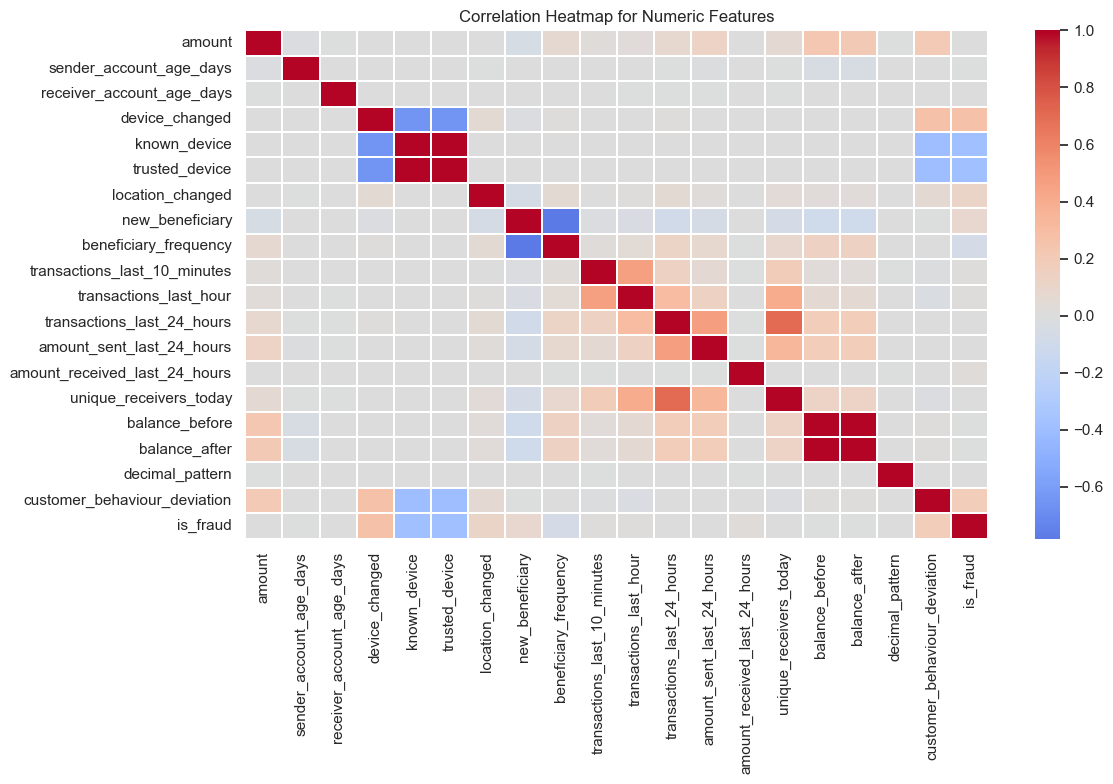

In [6]:
numeric_columns = df.select_dtypes(include=['int64', 'float64', 'bool']).copy()
correlation_matrix = numeric_columns.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Correlation Heatmap for Numeric Features')
plt.tight_layout()
plt.show()